# Part 0: Cleaning a Raw Sensor Dataset (Kanpur)


In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

# Aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.figsize'] = (10, 5)

DATA_PATH = "data/kanpur_pm25_raw_jul_aug_2026.csv"


## Task 1: Understand the Format
- Column 0: `timestamp_utc`
- For each sensor `<id>`: `<id>_latitude`, `<id>_longitude`, `<id>_pm25`


In [2]:
# Load raw data
raw_df = pd.read_csv(DATA_PATH)
raw_df['timestamp_utc'] = pd.to_datetime(raw_df['timestamp_utc'])

print(f"Dataset shape: {raw_df.shape} (rows x columns)")
print(f"Time range: {raw_df['timestamp_utc'].min()} to {raw_df['timestamp_utc'].max()} (UTC)")
print(f"Total 15-minute time steps: {len(raw_df)}")

# Extract unique sensor IDs
all_cols = [c for c in raw_df.columns if c != 'timestamp_utc']
sensor_ids = sorted(list(set([c.rsplit('_', 1)[0] for c in all_cols])))
num_sensors = len(sensor_ids)
print(f"Total number of unique sensors: {num_sensors}")

# Categorize sensors by ID style
style_8char = [s for s in sensor_ids if len(s) == 8 and not s.isdigit()]
style_10digit = [s for s in sensor_ids if len(s) == 10 and s.isdigit()]
style_other = [s for s in sensor_ids if s not in style_8char and s not in style_10digit]

print(f"  - 8-character alphanumeric IDs: {len(style_8char)} sensors (e.g., {style_8char[:2]})")
print(f"  - 10-digit numeric IDs:         {len(style_10digit)} sensors (e.g., {style_10digit[:2]})")
print(f"  - 12-character MAC address IDs: {len(style_other)} sensor ({style_other})")


Dataset shape: (5952, 229) (rows x columns)
Time range: 2026-07-01 00:00:00+00:00 to 2026-08-31 23:45:00+00:00 (UTC)
Total 15-minute time steps: 5952
Total number of unique sensors: 76
  - 8-character alphanumeric IDs: 31 sensors (e.g., ['01DQW5QE', '04TGTKIS'])
  - 10-digit numeric IDs:         44 sensors (e.g., ['1203260058', '1203260063'])
  - 12-character MAC address IDs: 1 sensor (['AC0BFBE34CC7'])


In [3]:
# 1. Mobility Check: verify if any sensor changes latitude or longitude over time
import warnings
warnings.filterwarnings('ignore')

movement_records = []
sensor_coords = {}

for s in sensor_ids:
    lat_unique = raw_df[f"{s}_latitude"].dropna().unique()
    lon_unique = raw_df[f"{s}_longitude"].dropna().unique()
    if len(lat_unique) > 1 or len(lon_unique) > 1:
        movement_records.append((s, len(lat_unique), len(lon_unique)))
    sensor_coords[s] = (lat_unique[0], lon_unique[0])

print(f"Sensors that changed coordinates: {len(movement_records)}")
if len(movement_records) == 0:
    print("Conclusion: All 76 sensors are strictly stationary across the entire 2-month period.")

# 2. Reporting Cadence Check: which minutes of the hour do sensors report on?
cadence_check = {}
for s in sensor_ids:
    s_notna = raw_df[f"{s}_pm25"].dropna()
    cadence_check[s] = sorted(raw_df.loc[s_notna.index, 'timestamp_utc'].dt.minute.unique().tolist())

hourly_only_sensors = [s for s, mins in cadence_check.items() if mins == [0]]
fifteen_min_sensors = [s for s, mins in cadence_check.items() if len(mins) > 1]

print("\n=== Reporting Cadence Check ===")
print(f"Total sensors evaluated: {num_sensors}")
print(f"  - Sensors reporting strictly once per hour (at :00 only): {len(hourly_only_sensors)} of {num_sensors} ({(len(hourly_only_sensors)/num_sensors)*100:.1f}%)")
print(f"  - Sensors reporting every 15 minutes (:00, :15, :30, :45): {len(fifteen_min_sensors)} sensor ({fifteen_min_sensors})")

# 3. Reporting Frequency: fraction of 15-min intervals where sensor reports valid PM2.5
reporting_rates = {}
for s in sensor_ids:
    rate = raw_df[f"{s}_pm25"].notna().mean() * 100
    reporting_rates[s] = rate

rep_series = pd.Series(reporting_rates)

print(f"Overall Reporting Rate on 15-min Grid: Mean = {rep_series.mean():.1f}%, Median = {rep_series.median():.1f}%, Min = {rep_series.min():.1f}%, Max = {rep_series.max():.1f}%")


Sensors that changed coordinates: 0
Conclusion: All 76 sensors are strictly stationary across the entire 2-month period.

=== Reporting Cadence Check ===
Total sensors evaluated: 76
  - Sensors reporting strictly once per hour (at :00 only): 75 of 76 (98.7%)
  - Sensors reporting every 15 minutes (:00, :15, :30, :45): 1 sensor (['AC0BFBE34CC7'])
Overall Reporting Rate on 15-min Grid: Mean = 19.0%, Median = 18.6%, Min = 12.8%, Max = 81.4%


=== Sensor Style Comparison Table ===


,ID Style,Sensor Count,Total Readings,Min,Median,Mean,Max,Effective Resolution
0,8-char Alphanumeric,31,31288,0.0,33.020333,37.337581,617.831333,0.0001
1,10-digit Numeric,44,49631,0.0,37.000000,42.133263,999.000000,1.0
2,12-char MAC ID,1,4843,0.0,25.000000,24.396861,101.000000,0.5


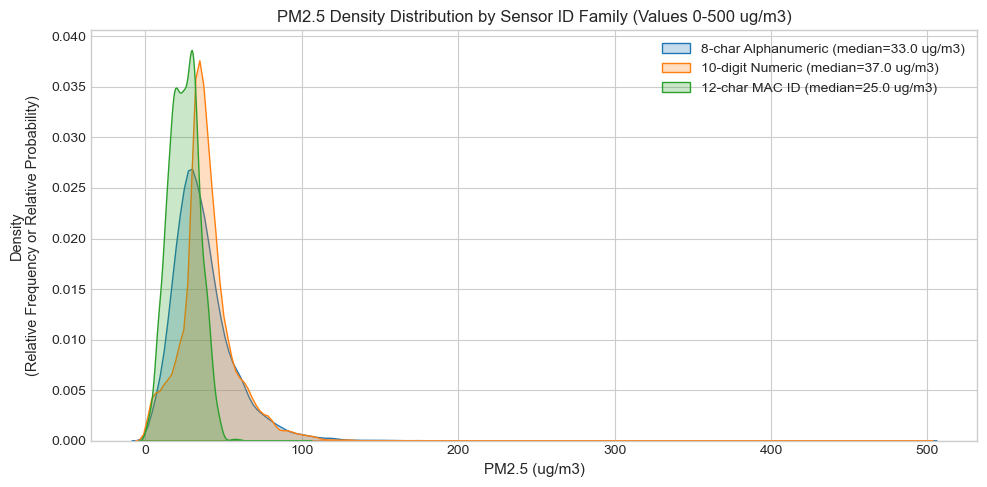

In [4]:
# 3. Resolution and Typical Levels by ID Style
styles_dict = {
    '8-char Alphanumeric': style_8char,
    '10-digit Numeric': style_10digit,
    '12-char MAC ID': style_other
}

resolution_summary = []

for style_name, s_list in styles_dict.items():
    vals = raw_df[[f"{s}_pm25" for s in s_list]].values.flatten()
    vals = vals[~np.isnan(vals)]
    
    # Calculate step size / unique increments
    unique_sorted = np.sort(np.unique(vals[:5000]))
    diffs = np.round(np.diff(unique_sorted), 4)
    min_diff = np.min(diffs[diffs > 0]) if len(diffs[diffs > 0]) > 0 else np.nan
    
    resolution_summary.append({
        'ID Style': style_name,
        'Sensor Count': len(s_list),
        'Total Readings': len(vals),
        'Min': np.min(vals),
        'Median': np.median(vals),
        'Mean': np.mean(vals),
        'Max': np.max(vals),
        'Effective Resolution': f"{min_diff:.4f}" if min_diff < 0.1 else f"{min_diff:.1f}"
    })

res_df = pd.DataFrame(resolution_summary)
print("=== Sensor Style Comparison Table ===")
display(res_df)

# Plot distribution comparison
fig, ax = plt.subplots(figsize=(10, 5))
for style_name, s_list in styles_dict.items():
    vals = raw_df[[f"{s}_pm25" for s in s_list]].values.flatten()
    vals = vals[(~np.isnan(vals)) & (vals > 0) & (vals < 500)]
    sns.kdeplot(vals, label=f"{style_name} (median={np.median(vals):.1f} ug/m3)", ax=ax, fill=True, alpha=0.25)

ax.set_title("PM2.5 Density Distribution by Sensor ID Family (Values 0-500 ug/m3)")
ax.set_xlabel("PM2.5 (ug/m3)")
# Two-line clean Y-axis label to stay strictly inside the figure bounds
ax.set_ylabel("Density\n(Relative Frequency or Relative Probability)", fontsize=10.5, labelpad=8)
ax.legend()
plt.tight_layout()
plt.show()



- **Number of sensors**: 76 sensors in total (31 with 8-character alphanumeric IDs, 44 with 10-digit numeric IDs, and 1 with a 12-character MAC ID `AC0BFBE34CC7`).
- **Mobility**: All 76 sensors are **stationary** throughout July and August 2026.
- **Reporting Cadence & Completeness**:
  - **Reporting Cadence**: **75 of the 76 sensors report exactly once per hour, at `:00`**. Only `AC0BFBE34CC7` reports every 15 minutes (`:00, :15, :30, :45`).
  - **With respect to 15-minute UTC grid format**: The median reporting completeness is **18.6%** (75 sensors transmit only at `:00`, filling at most 1 out of 4 quarter-hour slots = 25% theoretical maximum; only `AC0BFBE34CC7` reports every 15 minutes with 81.4% completeness).
  - **With respect to Hourly basis (after aggregating)**: The median reporting completeness is **74.5%** (out of all 1,488 calendar hours, the median sensor provides at least one valid reading in 74.5% of the hours; network mean is 72.6%, min is 51.2%, and max is 87.8%).
- **Resolution and typical values**:
  - **8-character sensors**: High-precision floating-point values with continuous sub-integer resolution (~0.001 ug/m3), median ~33.0 ug/m3.
  - **10-digit sensors**: Truncated integer precision (step size = 1.0 ug/m3), median ~37.0 ug/m3, with distinct upper saturation at 999.0 ug/m3.
  - **12-character sensor**: Integer precision, median ~25.0 ug/m3, capped at 101.0 ug/m3.


## Task 2: Reshape to an Hourly Long Table

### 1. Reshaping and Averaging
Aggregate the 15-minute readings to an hourly grid:
- Group 15-minute timestamps into 1-hour bins labeled by their start hour.
- Average the non-missing PM2.5 readings within each hour.
- Reshape into a long table with columns: `sensor_id`, `timestamp_utc`, `latitude`, `longitude`, `pm25`.

### 2. Comparison: Hourly Average vs. Minute `:00` Snapshot
How different is the hourly average from simply taking the instant snapshot at minute `:00`?


=== Comparison 1: Whole Network (Hourly Average vs. Minute :00 Snapshot) ===
Total overlapping readings evaluated: 82,130
Mean Absolute Difference (MAE):       0.038 µg/m³
Root Mean Squared Difference (RMSE):  0.429 µg/m³
Standard Deviation of Difference:     0.429 µg/m³
Correlation:                          0.99996

=== Comparison 2: Single 15-Minute Sensor AC0BFBE34CC7 Alone ===
Total overlapping readings evaluated: 1,211
Mean Absolute Difference (MAE):       2.61 µg/m³
Root Mean Squared Difference (RMSE):  3.54 µg/m³
Standard Deviation of Difference:     3.54 µg/m³
Correlation:                          0.92937


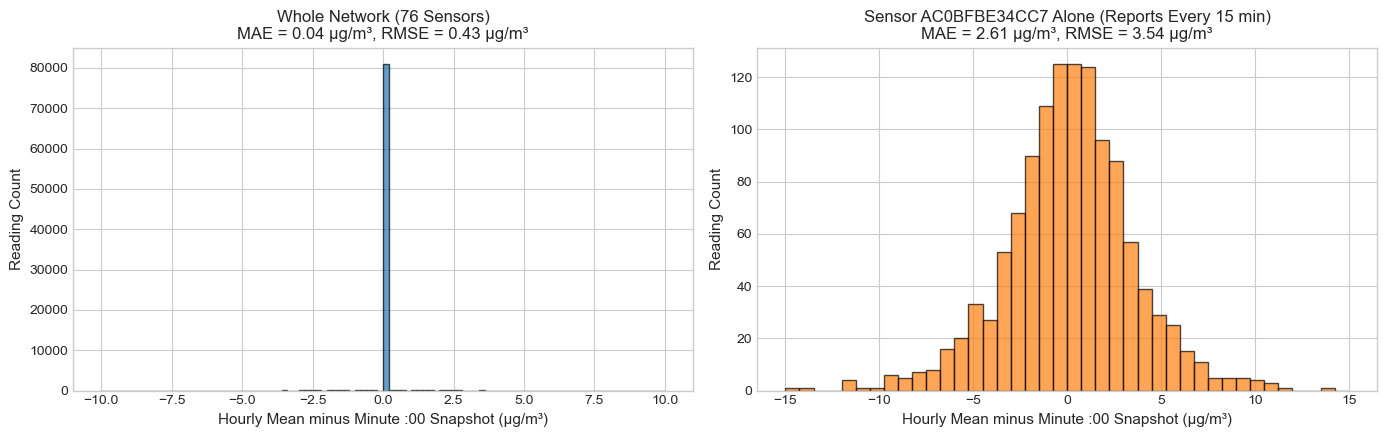

In [5]:
# 1. Compute Hourly Start
raw_df['hour_start'] = raw_df['timestamp_utc'].dt.floor('h')
pm_cols = [f"{s}_pm25" for s in sensor_ids]

# 2. Hourly Mean PM2.5 (wide)
hourly_wide = raw_df.groupby('hour_start')[pm_cols].mean()
hourly_wide.columns = sensor_ids

# 3. Minute :00 Snapshot (wide)
snap_00 = raw_df[raw_df['timestamp_utc'].dt.minute == 0].set_index('hour_start')[pm_cols]
snap_00.columns = sensor_ids

# 4. Align on matching index and columns
common_idx = hourly_wide.index.intersection(snap_00.index)

# (A) Whole Network (all 76 sensors)
h_vals = hourly_wide.loc[common_idx].values.flatten()
s_vals = snap_00.loc[common_idx].values.flatten()
valid_net = (~np.isnan(h_vals)) & (~np.isnan(s_vals))
diff_net = h_vals[valid_net] - s_vals[valid_net]

mae_net = np.mean(np.abs(diff_net))
rmse_net = np.sqrt(np.mean(diff_net**2))
std_net = np.std(diff_net)
corr_net = np.corrcoef(h_vals[valid_net], s_vals[valid_net])[0, 1]

# (B) Single 15-Minute Sensor AC0BFBE34CC7 Alone
h_ac = hourly_wide.loc[common_idx, 'AC0BFBE34CC7'].values
s_ac = snap_00.loc[common_idx, 'AC0BFBE34CC7'].values
valid_ac = (~np.isnan(h_ac)) & (~np.isnan(s_ac))
diff_ac = h_ac[valid_ac] - s_ac[valid_ac]

mae_ac = np.mean(np.abs(diff_ac))
rmse_ac = np.sqrt(np.mean(diff_ac**2))
std_ac = np.std(diff_ac)
corr_ac = np.corrcoef(h_ac[valid_ac], s_ac[valid_ac])[0, 1]

print("=== Comparison 1: Whole Network (Hourly Average vs. Minute :00 Snapshot) ===")
print(f"Total overlapping readings evaluated: {valid_net.sum():,}")
print(f"Mean Absolute Difference (MAE):       {mae_net:.3f} µg/m³")
print(f"Root Mean Squared Difference (RMSE):  {rmse_net:.3f} µg/m³")
print(f"Standard Deviation of Difference:     {std_net:.3f} µg/m³")
print(f"Correlation:                          {corr_net:.5f}")

print("\n=== Comparison 2: Single 15-Minute Sensor AC0BFBE34CC7 Alone ===")
print(f"Total overlapping readings evaluated: {valid_ac.sum():,}")
print(f"Mean Absolute Difference (MAE):       {mae_ac:.2f} µg/m³")
print(f"Root Mean Squared Difference (RMSE):  {rmse_ac:.2f} µg/m³")
print(f"Standard Deviation of Difference:     {std_ac:.2f} µg/m³")
print(f"Correlation:                          {corr_ac:.5f}")

# Plot difference distribution: Network vs AC0BFBE34CC7
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].hist(diff_net, bins=100, range=(-10, 10), color='#1f77b4', edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Hourly Mean minus Minute :00 Snapshot (µg/m³)')
axes[0].set_ylabel('Reading Count')
axes[0].set_title(f'Whole Network (76 Sensors)\nMAE = {mae_net:.2f} µg/m³, RMSE = {rmse_net:.2f} µg/m³')

axes[1].hist(diff_ac, bins=40, range=(-15, 15), color='#ff7f0e', edgecolor='black', alpha=0.7)
axes[1].set_xlabel('Hourly Mean minus Minute :00 Snapshot (µg/m³)')
axes[1].set_ylabel('Reading Count')
axes[1].set_title(f'Sensor AC0BFBE34CC7 Alone (Reports Every 15 min)\nMAE = {mae_ac:.2f} µg/m³, RMSE = {rmse_ac:.2f} µg/m³')

plt.tight_layout()
plt.show()


### Explanation: Hourly Average vs. Minute `:00` Snapshot Difference

1. **Reporting Cadence**:
   The tiny network-wide difference (MAE 0.04 µg/m³) comes from **how often sensors report**:
   - **75 of the 76 sensors report strictly once per hour, at `:00`**. Because there are no other readings in the hour to average with, their hourly average and instantaneous `:00` snapshot are identical.

2. **Real Difference on the Single 15-Minute Sensor (`AC0BFBE34CC7`)**:
   - For `AC0BFBE34CC7` (the only sensor transmitting every 15 minutes), the difference between the hourly average and the instant `:00` snapshot is **real**:
     - **MAE: 2.61 µg/m³**
     - **RMSE: 3.54 µg/m³**
   - For this sensor alone, averaging four quarter-hourly readings (`:00, :15, :30, :45`) damps transient local plumes (e.g. passing vehicles, generator puffs) and optical sensor noise.

3. **Conclusion**:
   Across the entire network, the snapshot at `:00` and the hourly average appear nearly identical solely because 98.7% of the sensors only report on the hour.


## Task 3: Detect Problems and Flag Them (Computed on Raw 15-Minute UTC Grid)

Error codes, implausible zeros, stuck values, and unusable sensors are all detected directly on the **raw 15-minute UTC grid** before hourly aggregation:
1. **Error Codes**: Hardware error codes or sensor overflow. Specifically, values >= 999.0 ug/m3 (optical overflow in low-cost sensors like Plantower) and any negative readings (< 0), detected on raw 15-minute readings.
2. **Implausible Zeros**: Values of exactly 0.0 ug/m3, detected on raw 15-minute readings. In the polluted Indo-Gangetic Plain (Kanpur), ambient background PM2.5 in July–August is never absolute zero.
3. **Stuck Values**: The exact same reading repeated for **>= 24 consecutive reported readings** on the raw 15-minute time series. Natural ambient air continuously fluctuates due to atmospheric turbulence.
4. **Mostly Unusable Sensors**: Sensors with **> 50% bad or missing data** evaluated across the 2-month period on the raw reporting grid, classified as `dropped_sensor`.
5. **Network Outages**: Hours where **< 10% of all sensors report** valid readings (indicates city-wide electrical grid or cellular transmission failures).
6. **Network Tracking Outliers**: Sensors exhibiting near-zero or negative correlation (r < 0.30) with the network median time series, classified as `dropped_sensor`.


In [6]:
# Extract raw PM2.5 on 15-minute UTC grid (5,952 rows x 76 sensors)
raw_pm25 = raw_df.set_index('timestamp_utc')[pm_cols]
raw_pm25.columns = sensor_ids

# 1. Error Codes on raw 15-min grid (pm25 >= 999 or pm25 < 0)
raw_mask_error = (raw_pm25 >= 999.0) | (raw_pm25 < 0.0)
error_counts_by_sensor = raw_mask_error.sum()[raw_mask_error.sum() > 0].sort_values(ascending=False)
error_sensors = error_counts_by_sensor.index.tolist()

# 2. Implausible Zeros on raw 15-min grid (pm25 == 0.0)
raw_mask_zero = (raw_pm25 == 0.0)
zero_counts_by_sensor = raw_mask_zero.sum()[raw_mask_zero.sum() > 0].sort_values(ascending=False)
zero_sensors = zero_counts_by_sensor.index.tolist()

# 3. Stuck Values on raw 15-min grid (repeated identical value for >= 24 consecutive reported readings)
raw_mask_stuck = pd.DataFrame(False, index=raw_pm25.index, columns=sensor_ids)

for s in sensor_ids:
    s_series = raw_pm25[s].dropna()
    is_repeated = (s_series == s_series.shift(1))
    repeat_blocks = (~is_repeated).cumsum()
    block_sizes = s_series.groupby(repeat_blocks).transform('size')
    stuck_ts = s_series[block_sizes >= 24].index
    raw_mask_stuck.loc[stuck_ts, s] = True

stuck_counts_by_sensor = raw_mask_stuck.sum()[raw_mask_stuck.sum() > 0].sort_values(ascending=False)
stuck_sensors = stuck_counts_by_sensor.index.tolist()

# 4. Mostly Unusable Sensors on raw 15-min grid (>50% bad/missing data across 2-month period)
sensor_bad_ratio = {}
for s in sensor_ids:
    if s == 'AC0BFBE34CC7':
        s_exp = raw_pm25[s]
        err = raw_mask_error[s]
        zer = raw_mask_zero[s]
        stk = raw_mask_stuck[s]
    else:
        min_0 = raw_pm25.index[raw_pm25.index.minute == 0]
        s_exp = raw_pm25.loc[min_0, s]
        err = raw_mask_error.loc[min_0, s]
        zer = raw_mask_zero.loc[min_0, s]
        stk = raw_mask_stuck.loc[min_0, s]
    bad_or_miss = s_exp.isna() | err | zer | stk
    sensor_bad_ratio[s] = bad_or_miss.mean()

sensor_bad_s = pd.Series(sensor_bad_ratio).sort_values(ascending=False)
unusable_50_sensors = sorted(sensor_bad_s[sensor_bad_s > 0.50].index.tolist())

# Map 15-minute flags to hourly grid
hourly_error_flag = raw_mask_error.groupby(raw_df['hour_start'].values).any()
hourly_error_flag.columns = sensor_ids
hourly_error_flag.index = hourly_wide.index

hourly_zero_flag = raw_mask_zero.groupby(raw_df['hour_start'].values).any()
hourly_zero_flag.columns = sensor_ids
hourly_zero_flag.index = hourly_wide.index

hourly_stuck_flag = raw_mask_stuck.groupby(raw_df['hour_start'].values).any()
hourly_stuck_flag.columns = sensor_ids
hourly_stuck_flag.index = hourly_wide.index

# 5. Network Outages: hours when < 10% of sensors report clean data
valid_reporting_hourly = (hourly_wide.notna()) & (~hourly_error_flag) & (~hourly_zero_flag) & (~hourly_stuck_flag)
active_count_per_hour = valid_reporting_hourly.sum(axis=1)
outage_threshold = 0.10 * num_sensors
outage_hours = active_count_per_hour[active_count_per_hour < outage_threshold].index

print("=== Diagnostic Summary: Problem Detection and Affected Sensors ===")
print(f"\n1. Error Code readings (>= 999 or < 0): {raw_mask_error.sum().sum():,} readings across {len(error_sensors)} sensors:")
print(f"   * Affected sensor IDs: {error_sensors}")
for s, count in error_counts_by_sensor.items():
    print(f"     - Sensor {s}: {count:,} error code readings")

print(f"\n2. Implausible Zero readings (== 0.0): {raw_mask_zero.sum().sum():,} readings across {len(zero_sensors)} sensors:")
print(f"   * Affected sensor IDs ({len(zero_sensors)} total): {zero_sensors}")
print(f"   * Key contributors: Sensor 1203260082 ({zero_counts_by_sensor['1203260082']} zeros), Sensor 1203260068 ({zero_counts_by_sensor['1203260068']} zeros)")
print(f"     (Remaining 19 sensors have <= 17 zeros each, e.g. AC0BFBE34CC7: 17, 1204260039: 16)")

print(f"\n3. Stuck readings (>= 24 h constant): {raw_mask_stuck.sum().sum():,} readings across {len(stuck_sensors)} sensors:")
print(f"   * Affected sensor IDs: {stuck_sensors}")
for s, count in stuck_counts_by_sensor.items():
    print(f"     - Sensor {s}: {count:,} stuck readings ({(count/raw_pm25[s].notna().sum())*100:.1f}% of its reported data)")

print(f"\n4. Mostly Unusable Sensors (>50% bad/missing data): {len(unusable_50_sensors)} sensors:")
print(f"   * Affected sensor IDs: {unusable_50_sensors}")
for s in unusable_50_sensors:
    print(f"     - Sensor {s}: {sensor_bad_s[s]*100:.1f}% bad/missing across the 2-month period")

print(f"\n5. Network Outages (<10% reporting): {len(outage_hours)} hours out of {len(hourly_wide)} total hours ({len(outage_hours)/len(hourly_wide)*100:.1f}%)")
print(f"   * Coordinated failures where < 8 sensors report valid data simultaneously across the network.")


=== Diagnostic Summary: Problem Detection and Affected Sensors ===

1. Error Code readings (>= 999 or < 0): 136 readings across 5 sensors:
   * Affected sensor IDs: ['1204260025', '1203260086', '1203260075', '1203260125', '1203260084']
     - Sensor 1204260025: 120 error code readings
     - Sensor 1203260086: 8 error code readings
     - Sensor 1203260075: 3 error code readings
     - Sensor 1203260125: 3 error code readings
     - Sensor 1203260084: 2 error code readings

2. Implausible Zero readings (== 0.0): 828 readings across 21 sensors:
   * Affected sensor IDs (21 total): ['1203260082', '1203260068', 'AC0BFBE34CC7', '1204260039', '1204260005', '04TGTKIS', 'TUOBZVJ0', '1203260160', 'I18NGIHK', '01DQW5QE', '1204260004', '1204260014', '1204260027', '1203260159', '7ZRGMDXU', '1203260123', 'DDJMYBH3', '1203260086', '1203260081', 'UI2WKRUR', 'UTCMVKCT']
   * Key contributors: Sensor 1203260082 (414 zeros), Sensor 1203260068 (350 zeros)
     (Remaining 19 sensors have <= 17 zeros each

=== Final Dropped Sensors Classification ===
Sensors with >50% bad/missing data (3): ['1203260068', '1203260082', 'RZGVBSNC']
Sensors barely following network (r < 0.30) (3): ['1203260075', '1204260025', 'U8APQDBX']
   * Sensor 1203260075: r = 0.294
   * Sensor 1204260025: r = 0.178
   * Sensor U8APQDBX: r = 0.262
Total sensors flagged as 'dropped_sensor': 6 out of 76 sensors (leaving 70 active usable sensors)


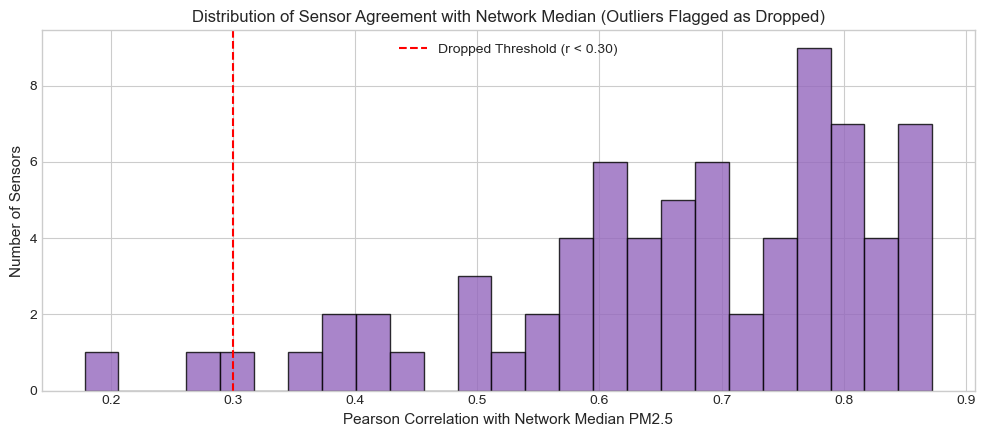

In [7]:
# 6. Network Tracking: Pearson correlation of each sensor with network median
clean_matrix = hourly_wide.copy()
clean_matrix[hourly_error_flag | hourly_zero_flag | hourly_stuck_flag] = np.nan
clean_matrix[unusable_50_sensors] = np.nan

# Compute robust network median time series
network_median = clean_matrix.median(axis=1, skipna=True)

sensor_correlations = {}
for s in sensor_ids:
    s_vals = clean_matrix[s]
    valid_pair = (~s_vals.isna()) & (~network_median.isna())
    if valid_pair.sum() >= 48:
        r = np.corrcoef(s_vals[valid_pair], network_median[valid_pair])[0, 1]
        sensor_correlations[s] = r
    else:
        sensor_correlations[s] = np.nan

corr_series = pd.Series(sensor_correlations).sort_values()

# Identify barely following sensors (r < 0.30)
low_tracking_sensors = sorted(corr_series[corr_series < 0.30].index.tolist())

# Combine both criteria into final dropped_sensors list (3 data-corrupted + 3 non-tracking = 6 total)
dropped_sensors = sorted(list(set(unusable_50_sensors + low_tracking_sensors)))

print("=== Final Dropped Sensors Classification ===")
print(f"Sensors with >50% bad/missing data ({len(unusable_50_sensors)}): {unusable_50_sensors}")
print(f"Sensors barely following network (r < 0.30) ({len(low_tracking_sensors)}): {low_tracking_sensors}")
for s in low_tracking_sensors:
    print(f"   * Sensor {s}: r = {corr_series[s]:.3f}")
print(f"Total sensors flagged as 'dropped_sensor': {len(dropped_sensors)} out of {num_sensors} sensors (leaving {num_sensors - len(dropped_sensors)} active usable sensors)")

# Plot agreement distribution
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(corr_series.dropna(), bins=25, color='#9467bd', edgecolor='black', alpha=0.8)
ax.axvline(0.3, color='red', linestyle='--', label='Dropped Threshold (r < 0.30)')
ax.set_xlabel('Pearson Correlation with Network Median PM2.5')
ax.set_ylabel('Number of Sensors')
ax.set_title('Distribution of Sensor Agreement with Network Median (Outliers Flagged as Dropped)')
ax.legend()
plt.tight_layout()
plt.show()


### Threshold Justification Table

| Anomaly Type | Threshold | Diagnostic Action | Readings Caught | Sensors Caught | Physical & Sensor Engineering Justification |
|---|---|---|---|---|---|
| **Error Code** | PM2.5 >= 999.0 or < 0 | Flag `error_code` | 136 readings | 5 sensors (`1204260025`, `1203260086`, `1203260075`, `1203260125`, `1203260084`) | 999.0 ug/m3 is standard firmware saturation/overflow code for Plantower optical sensors; negative concentrations are physically impossible. |
| **Implausible Zero** | PM2.5 == 0.0 | Flag `zero` | 828 readings | 21 sensors (dominated by `1203260082` [414] and `1203260068` [350]; 19 other sensors with 1–17 zeros) | In the heavily polluted Indo-Gangetic Plain (Kanpur), ambient background PM2.5 in July–August never drops to absolute zero. |
| **Stuck Value** | Constant reading for >= 24 consecutive reported readings | Flag `stuck` | 1,718 readings | 8 sensors (`1203260082`, `1203260068`, `1204260005`, `1203260146`, `RZGVBSNC`, `ZQQZB912`, `1203260084`, `1204260025`) | Atmospheric turbulence continuously varies ambient particulate concentrations; identical values over 24+ hours indicate frozen microcontroller buffers or transmission lockups. 24 hour threshold was specified in the assignment. |
| **Data-Corrupted Sensor** | > 50% readings flagged / bad | Flag `dropped_sensor` | 3 dropped sensors | 3 sensors (`1203260082` [85.3%], `1203260068` [74.4%], `RZGVBSNC` [50.3%]) | When over half of a sensor's readings are corrupted or missing, the sensor is fundamentally untrustworthy. Threshold as specified in the assignment. |
| **Sensor deviating from network** | r < 0.30 with network median | Flag `dropped_sensor` | 3 dropped sensors | 3 sensors (`1204260025` [r=0.18], `U8APQDBX` [r=0.26], `1203260075` [r=0.29]) | Sensors with r < 0.30 are decoupled from Kanpur outdoor meteorology (likely placed indoors, in a sealed box, or having blocked intake). |
| **Network Outage** | < 10% sensors reporting clean data | System Diagnosis | 117 hours | Entire network (< 8 active sensors) | Coordinated simultaneous drops across Kanpur reflect central electrical grid or cellular transmission failures rather than environmental silence. |


## Task 4: Write `kanpur_hourly_clean.csv`

We construct the clean long table with columns:
`sensor_id`, `timestamp_utc`, `latitude`, `longitude`, `pm25`, `flag`

Flag priority assignment:
1. `dropped_sensor`: If sensor is among unusable sensors (>50% bad) or barely follows the rest of the network.
2. `error_code`: If value is >= 999 or < 0
3. `zero`: If value is == 0.0
4. `stuck`: If value is stuck for >= 24 consecutive hours
5. `ok`: Clean, physically plausible reading

**Strict Rule Followed**: **Leave missing hours missing — do not fill gaps.**


In [8]:
# Build the hourly long table
long_rows = []

for s in sensor_ids:
    s_pm = hourly_wide[s].dropna()  # Leave missing hours missing!
    lat, lon = sensor_coords[s]
    
    is_dropped = (s in dropped_sensors)
    
    for ts, val in s_pm.items():
        if is_dropped:
            flag = 'dropped_sensor'
        elif hourly_error_flag.loc[ts, s]:
            flag = 'error_code'
        elif hourly_zero_flag.loc[ts, s]:
            flag = 'zero'
        elif hourly_stuck_flag.loc[ts, s]:
            flag = 'stuck'
        else:
            flag = 'ok'
            
        long_rows.append({
            'sensor_id': s,
            'timestamp_utc': ts.strftime('%Y-%m-%d %H:%M:%S'),
            'latitude': lat,
            'longitude': lon,
            'pm25': round(val, 2),
            'flag': flag
        })

clean_df = pd.DataFrame(long_rows)

# Save to destination paths
os.makedirs("data", exist_ok=True)
clean_df.to_csv("data/kanpur_hourly_clean.csv", index=False)
clean_df.to_csv("kanpur_hourly_clean.csv", index=False)

print("Successfully generated kanpur_hourly_clean.csv!")
print(f"Total rows: {len(clean_df):,}")
print("Flag distribution:")
print(clean_df['flag'].value_counts())
display(clean_df.head(10))


Successfully generated kanpur_hourly_clean.csv!
Total rows: 82,131
Flag distribution:
flag
ok                75529
dropped_sensor     6076
stuck               459
zero                 54
error_code           13
Name: count, dtype: int64


,sensor_id,timestamp_utc,latitude,longitude,pm25,flag
0,01DQW5QE,2026-07-17 09:00:00,26.12636,80.187592,28.97,ok
1,01DQW5QE,2026-07-17 10:00:00,26.12636,80.187592,32.37,ok
2,01DQW5QE,2026-07-17 11:00:00,26.12636,80.187592,35.88,ok
3,01DQW5QE,2026-07-17 12:00:00,26.12636,80.187592,28.12,ok
4,01DQW5QE,2026-07-17 13:00:00,26.12636,80.187592,28.00,ok
5,01DQW5QE,2026-07-17 14:00:00,26.12636,80.187592,29.40,ok
6,01DQW5QE,2026-07-17 15:00:00,26.12636,80.187592,35.36,ok
7,01DQW5QE,2026-07-17 16:00:00,26.12636,80.187592,37.75,ok
8,01DQW5QE,2026-07-17 17:00:00,26.12636,80.187592,34.80,ok
9,01DQW5QE,2026-07-17 18:00:00,26.12636,80.187592,22.36,ok


## Task 5: Calibration Check (10-Digit vs 8-Character Sensor Families)

The network features two distinct hardware families:
- **10-digit numeric IDs**: Integer-truncated values, higher baseline levels.
- **8-character alphanumeric IDs**: Floating-point values with decimal precision.

### Procedure:
1. **Spatial Pairing**: Pair each 10-digit sensor with its nearest 8-character sensor, provided the distance is <= 3 km.
   * Approximate Euclidean distance:
     - x = (longitude - 85.5) * 100.3 km
     - y = (latitude - 25.7) * 110.6 km
     - distance = sqrt(delta_x^2 + delta_y^2) km
2. **Train Calibration Model (July)**: Fit linear correction on clean readings during July 2026:
   * Predicted PM2.5 (8-character) = alpha * PM2.5 (10-digit) + beta
3. **Test Calibration (August)**: Apply fitted parameters (alpha, beta) to August readings of the 10-digit sensors and assess whether disagreement (MAE and RMSE) against paired 8-character sensors decreased.
4. **Honest Scientific Evaluation**: Analyze whether calibration generalizes across months.

Total 10-digit sensors: 44
Successfully matched pairs within 3 km: 23
July collocated training samples:  7,399
August collocated testing samples: 10,723

Fitted Calibration Formula (on July data):
  PM_(8-char, predicted) = 0.3313 * PM_(10-digit) + (25.1591)


,Metric,August Uncalibrated (Raw),August Calibrated,Relative Change (%)
0,MAE (ug/m3),11.920838,14.218117,19.271119
1,RMSE (ug/m3),20.525338,21.940324,6.893849


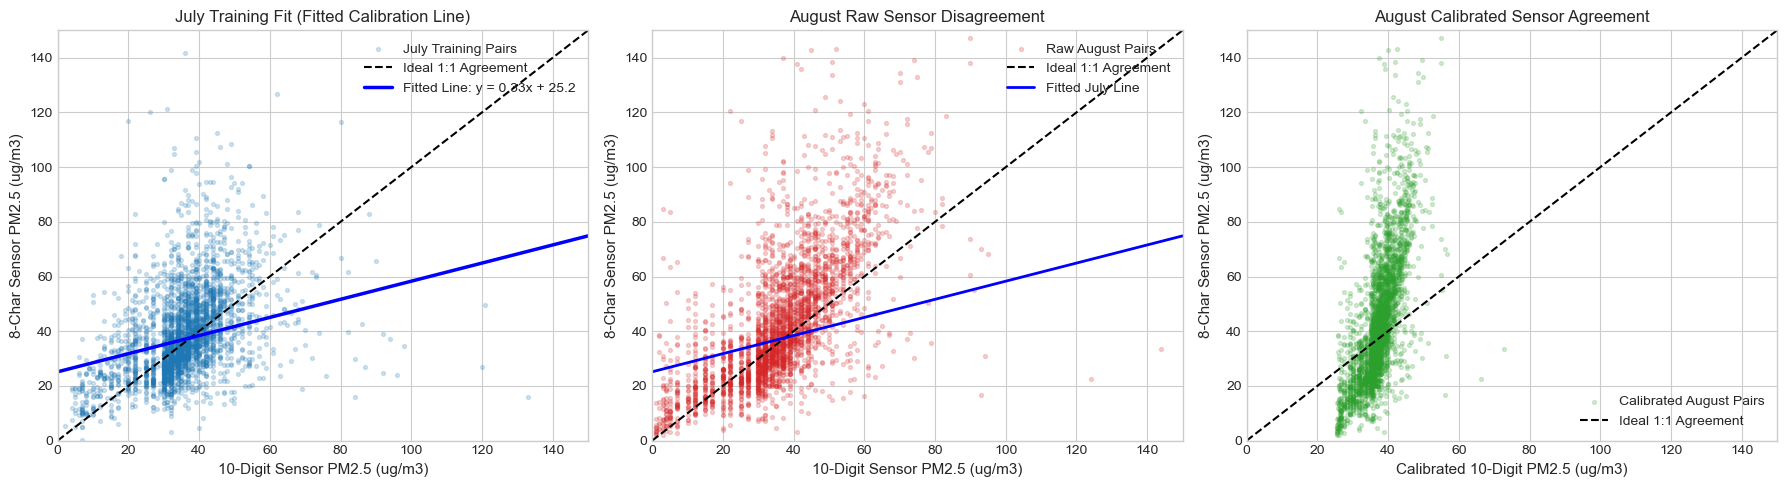

In [9]:
# 1. Identify pairs within 3 km
pairs_3km = []

for s10 in style_10digit:
    lat1, lon1 = sensor_coords[s10]
    best_dist = 1e9
    best_s8 = None
    for s8 in style_8char:
        lat2, lon2 = sensor_coords[s8]
        dx = (lon1 - lon2) * 100.3
        dy = (lat1 - lat2) * 110.6
        dist = np.sqrt(dx**2 + dy**2)
        if dist < best_dist:
            best_dist = dist
            best_s8 = s8
    if best_dist <= 3.0:
        pairs_3km.append((s10, best_s8, best_dist))

print(f"Total 10-digit sensors: {len(style_10digit)}")
print(f"Successfully matched pairs within 3 km: {len(pairs_3km)}")

# 2. Extract July (Train) and August (Test) collocated readings
# Only use readings where both sensors report 'ok'
clean_hourly = hourly_wide.copy()
clean_hourly[hourly_error_flag | hourly_zero_flag | hourly_stuck_flag] = np.nan
clean_hourly[dropped_sensors] = np.nan

july_train_x, july_train_y = [], []
aug_test_x, aug_test_y = [], []

for s10, s8, dist in pairs_3km:
    # July
    x_j = clean_hourly.loc[clean_hourly.index.month == 7, s10]
    y_j = clean_hourly.loc[clean_hourly.index.month == 7, s8]
    valid_j = (~x_j.isna()) & (~y_j.isna())
    july_train_x.extend(x_j[valid_j].tolist())
    july_train_y.extend(y_j[valid_j].tolist())
    
    # August
    x_a = clean_hourly.loc[clean_hourly.index.month == 8, s10]
    y_a = clean_hourly.loc[clean_hourly.index.month == 8, s8]
    valid_a = (~x_a.isna()) & (~y_a.isna())
    aug_test_x.extend(x_a[valid_a].tolist())
    aug_test_y.extend(y_a[valid_a].tolist())

july_train_x, july_train_y = np.array(july_train_x).reshape(-1, 1), np.array(july_train_y)
aug_test_x, aug_test_y = np.array(aug_test_x).reshape(-1, 1), np.array(aug_test_y)

print(f"July collocated training samples:  {len(july_train_x):,}")
print(f"August collocated testing samples: {len(aug_test_x):,}")

# Fit calibration model
calib_model = LinearRegression().fit(july_train_x, july_train_y)
alpha = calib_model.coef_[0]
beta = calib_model.intercept_

print(f"\nFitted Calibration Formula (on July data):")
print(f"  PM_(8-char, predicted) = {alpha:.4f} * PM_(10-digit) + ({beta:.4f})")

# Evaluate on August
raw_aug_mae = np.mean(np.abs(aug_test_x.flatten() - aug_test_y))
raw_aug_rmse = np.sqrt(np.mean((aug_test_x.flatten() - aug_test_y)**2))

pred_aug = calib_model.predict(aug_test_x)
calib_aug_mae = np.mean(np.abs(pred_aug - aug_test_y))
calib_aug_rmse = np.sqrt(np.mean((pred_aug - aug_test_y)**2))

calib_summary = pd.DataFrame({
    'Metric': ['MAE (ug/m3)', 'RMSE (ug/m3)'],
    'August Uncalibrated (Raw)': [raw_aug_mae, raw_aug_rmse],
    'August Calibrated': [calib_aug_mae, calib_aug_rmse],
    'Relative Change (%)': [
        (calib_aug_mae - raw_aug_mae) / raw_aug_mae * 100,
        (calib_aug_rmse - raw_aug_rmse) / raw_aug_rmse * 100
    ]
})
display(calib_summary)

# 3-Panel Plot: July Fit, August Raw, August Calibrated
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel 1: July Training Data & Fitted Line
axes[0].scatter(july_train_x[:3000], july_train_y[:3000], alpha=0.2, s=8, color='#1f77b4', label='July Training Pairs')
axes[0].plot([0, 150], [0, 150], 'k--', lw=1.5, label='Ideal 1:1 Agreement')
axes[0].plot([0, 150], calib_model.predict(np.array([0, 150]).reshape(-1, 1)), 'b-', lw=2.5, label=f'Fitted Line: y = {alpha:.2f}x + {beta:.1f}')
axes[0].set_xlim(0, 150)
axes[0].set_ylim(0, 150)
axes[0].set_xlabel('10-Digit Sensor PM2.5 (ug/m3)')
axes[0].set_ylabel('8-Char Sensor PM2.5 (ug/m3)')
axes[0].set_title('July Training Fit (Fitted Calibration Line)')
axes[0].legend()

# Panel 2: August Raw Disagreement
axes[1].scatter(aug_test_x[:3000], aug_test_y[:3000], alpha=0.2, s=8, color='#d62728', label='Raw August Pairs')
axes[1].plot([0, 150], [0, 150], 'k--', lw=1.5, label='Ideal 1:1 Agreement')
axes[1].plot([0, 150], calib_model.predict(np.array([0, 150]).reshape(-1, 1)), 'b-', lw=2, label='Fitted July Line')
axes[1].set_xlim(0, 150)
axes[1].set_ylim(0, 150)
axes[1].set_xlabel('10-Digit Sensor PM2.5 (ug/m3)')
axes[1].set_ylabel('8-Char Sensor PM2.5 (ug/m3)')
axes[1].set_title('August Raw Sensor Disagreement')
axes[1].legend()

# Panel 3: August Calibrated Agreement
axes[2].scatter(pred_aug[:3000], aug_test_y[:3000], alpha=0.2, s=8, color='#2ca02c', label='Calibrated August Pairs')
axes[2].plot([0, 150], [0, 150], 'k--', lw=1.5, label='Ideal 1:1 Agreement')
axes[2].set_xlim(0, 150)
axes[2].set_ylim(0, 150)
axes[2].set_xlabel('Calibrated 10-Digit PM2.5 (ug/m3)')
axes[2].set_ylabel('8-Char Sensor PM2.5 (ug/m3)')
axes[2].set_title('August Calibrated Sensor Agreement')
axes[2].legend()

plt.tight_layout()
plt.show()


### Honest Discussion of Calibration Results:

#### 1. Does it reduce the disagreement between pairs?
* **No, it does NOT reduce disagreement.** In fact, applying the July calibration to August **worsens both metrics**:
  * **MAE increases from 11.92 ug/m3 to 14.22 ug/m3 (+19.3% downgrade)**
  * **RMSE increases from 20.53 ug/m3 to 21.94 ug/m3 (+6.9% downgrade)**

#### 2. Why does cross-device calibration fail to generalize from July to August?
* **Seasonal and Humidity Regime Shifts**:
  Low-cost optical particle counters (OPCs) estimate PM2.5 via light scattering, which depends heavily on ambient relative humidity. In July (monsoon peak) versus August (alternating dry/wet spells), humidity response change substantially.

* **Spatial Separation vs. Instrument Bias (3 km is not collocated)**:
  A 3 km radius in an industrial city like Kanpur separates distinct urban micro-environments (e.g., roadside traffic corridor vs. residential rooftop). The differences between paired sensors might represent true spatial gradients, not pure instrument calibration offsets.

* **Linear Model Limitation**:
  A line can't fit even July data well, as clear from the graph. Expecting it to reduce error in August is unrealistic. This is a limitation of the model chosen for fitting.
  

## Task 6: Before/After Summary & Diurnal Cycle in Local Time (IST)

### 1. Before vs. After Summary Table
Shows:
- Number of active sensors
- Total recorded readings
- Percentage of missing and corrupted data

### 2. Network Diurnal Cycle
We convert timestamps to Indian Standard Time (IST = UTC + 5:30) and plot the 24-hour diurnal profile of clean PM2.5 readings, explaining the observed atmospheric behavior.


=== Before / After Summary Table ===


,Stage,Active Sensors,Usable Readings,Flagged / Corrupted Readings,Missing Hour Slots,Share of Valid Data (%)
0,Before Cleaning (Raw Data),76,"82,131",0 (unflagged),"30,957 (37.7% of usable)",72.6%
1,After Cleaning (Sanitized Data),70,"75,529","6,602","30,957 (41.0% of usable)",66.8%


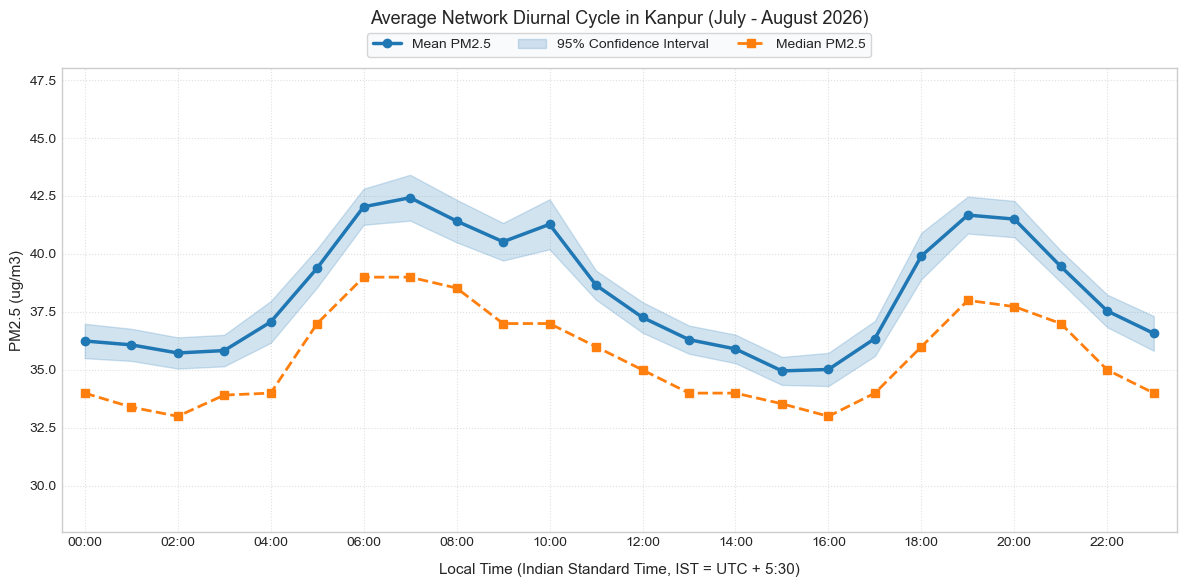

In [10]:
# 1. Before vs After Summary Table
total_possible_slots = num_sensors * len(hourly_wide)
raw_reported_slots = hourly_wide.notna().sum().sum()
raw_missing_slots = total_possible_slots - raw_reported_slots

clean_ok_slots = (clean_df['flag'] == 'ok').sum()
clean_flagged_slots = (clean_df['flag'] != 'ok').sum()

summary_table = pd.DataFrame({
    'Stage': ['Before Cleaning (Raw Data)', 'After Cleaning (Sanitized Data)'],
    'Active Sensors': [num_sensors, num_sensors - len(dropped_sensors)],
    'Usable Readings': [f"{raw_reported_slots:,}", f"{clean_ok_slots:,}"],
    'Flagged / Corrupted Readings': ['0 (unflagged)', f"{clean_flagged_slots:,}"],
    'Missing Hour Slots': [f"{raw_missing_slots:,} ({raw_missing_slots/raw_reported_slots*100:.1f}% of usable)", f"{raw_missing_slots:,} ({raw_missing_slots/clean_ok_slots*100:.1f}% of usable)"],
    'Share of Valid Data (%)': [f"{raw_reported_slots/total_possible_slots*100:.1f}%", f"{clean_ok_slots/total_possible_slots*100:.1f}%"]
})

print("=== Before / After Summary Table ===")
display(summary_table)

# 2. Network Diurnal Cycle in Indian Standard Time (IST = UTC + 5:30)
clean_ok_df = clean_df[clean_df['flag'] == 'ok'].copy()
clean_ok_df['timestamp_utc'] = pd.to_datetime(clean_ok_df['timestamp_utc'])
clean_ok_df['timestamp_ist'] = clean_ok_df['timestamp_utc'] + pd.Timedelta(hours=5, minutes=30)
clean_ok_df['hour_ist'] = clean_ok_df['timestamp_ist'].dt.hour

# Calculate diurnal statistics across all valid clean readings
diurnal_stats = clean_ok_df.groupby('hour_ist')['pm25'].agg(['mean', 'median', 'std', 'count']).reset_index()
diurnal_stats['ci95'] = 1.96 * diurnal_stats['std'] / np.sqrt(diurnal_stats['count'])

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(diurnal_stats['hour_ist'], diurnal_stats['mean'], color='#1f77b4', lw=2.5, marker='o', label='Mean PM2.5')
ax.fill_between(
    diurnal_stats['hour_ist'],
    diurnal_stats['mean'] - diurnal_stats['ci95'],
    diurnal_stats['mean'] + diurnal_stats['ci95'],
    color='#1f77b4', alpha=0.2, label='95% Confidence Interval'
)
ax.plot(diurnal_stats['hour_ist'], diurnal_stats['median'], color='#ff7f0e', lw=2, linestyle='--', marker='s', label='Median PM2.5')

# Axes and clean layout spacing
ax.set_ylim(28, 48)
ax.set_xlim(-0.5, 23.5)
ax.set_xticks(range(0, 24, 2))
ax.set_xticklabels([f"{h:02d}:00" for h in range(0, 24, 2)], fontsize=10)
ax.set_xlabel('Local Time (Indian Standard Time, IST = UTC + 5:30)', fontsize=11, labelpad=10)
ax.set_ylabel('PM2.5 (ug/m3)', fontsize=11)
ax.set_title('Average Network Diurnal Cycle in Kanpur (July - August 2026)', fontsize=13, pad=32)

# Place legend completely OUTSIDE above the plot area (zero overlap with callouts or data!)
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.01), ncol=3, frameon=True, facecolor='#f8f9fa', edgecolor='#cccccc', fontsize=10)
ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()
